# Stream events: arrival, duration, free profile, additive events (models.stream_events)

Structural model v2: Poisson arrivals with an intensity from the inputs, a duration and a
peak excess per arrival hour, a free piecewise-linear speed profile and a free relaxation
of the current excess; overlapping events add. Fitted in one step on the speed loss plus
the Poisson likelihood of the detected arrivals. Stopped after the 2024 pilot fold; study
`python -m training.stream_events`; write-up `docs/stream_events.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import model_diagnostics as dg
from training import stream_events as tse

d = pd.read_csv(tse.EXPERIMENTS / "stream_events.csv", dtype={"fold": str})
ref = d[d.variant == "reference"].set_index("fold")
rows = {}
for v, g in d.groupby("variant"):
    g = g.set_index("fold")
    rel = g["all"] / ref["all"]
    rows[v] = {"S_final": g["all"].iloc[0], "vs reference %": 100 * (rel.iloc[0] - 1),
               **{f"{r} %": 100 * (g[r].iloc[0] / ref[r].iloc[0] - 1) for r in dg.RUN_REGIMES}}
pd.DataFrame(rows).T.sort_values("vs reference %").round(2)

,S_final,vs reference %,CME %,stream arrival %,fast stream %,intermediate %,slow wind %
reference,107.81,0.00,0.00,0.00,0.00,0.00,0.00
events no PFSS,110.50,2.50,7.01,-0.09,-7.46,-11.86,8.52
linear + events,111.22,3.16,8.35,1.58,-7.17,-3.13,6.52
single event,120.97,12.21,19.97,9.79,-9.99,-0.05,21.01
events speed only,127.16,17.95,25.84,10.53,-4.02,7.74,34.55
events,129.62,20.23,28.16,10.95,3.58,7.30,35.80


## Fitted quantities and arrival skill (2024 fold)

In [2]:
p = pd.read_csv(tse.EXPERIMENTS / "stream_events_params.csv", dtype={"fold": str})
cols = ["variant", "loss", "speed_loss", "event_nll", "label_rate", "lambda mean /h",
        "duration mean h", "amplitude mean km/s", "arrival LL skill", "arrival AUC",
        "arrivals observed", "arrivals expected"]
p[cols].set_index("variant").round(4)

,loss,speed_loss,event_nll,label_rate,lambda mean /h,duration mean h,amplitude mean km/s,arrival LL skill,arrival AUC,arrivals observed,arrivals expected
variant,,,,,,,,,,,
events,0.6826,0.6476,0.0219,0.0028,0.0191,68.8833,330.299,-0.3868,0.6507,372,1935.100
events speed only,0.6592,0.6493,0.0320,0.0028,0.0411,63.9773,190.085,-1.1767,0.6487,372,4161.960
single event,0.6888,0.6578,0.0204,0.0028,0.0185,75.2461,495.348,-0.4709,0.6322,372,1906.190
events no PFSS,0.7482,0.7183,0.0222,0.0028,0.0093,69.9907,434.827,-0.0689,0.6935,372,940.277


## Learned speed profile phi and relaxation psi

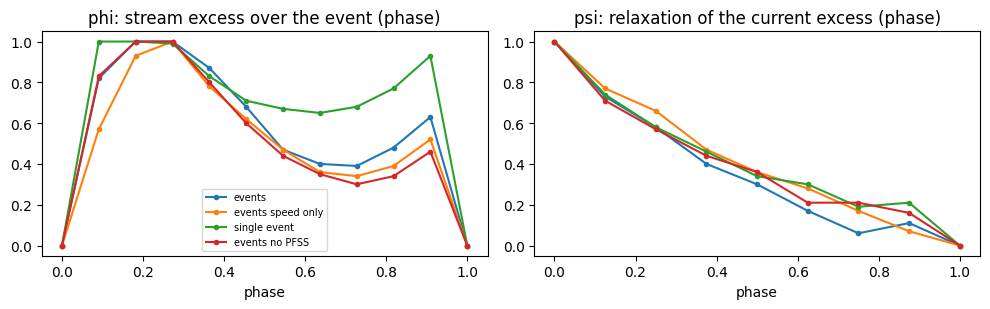

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for _, r in p.iterrows():
    phi = np.array(r["phi"].split(), dtype=float)
    psi = np.array(r["psi"].split(), dtype=float)
    axes[0].plot(np.linspace(0, 1, len(phi)), phi, marker=".", label=r["variant"])
    axes[1].plot(np.linspace(0, 1, len(psi)), psi, marker=".", label=r["variant"])
axes[0].set_title("phi: stream excess over the event (phase)")
axes[1].set_title("psi: relaxation of the current excess (phase)")
for ax in axes:
    ax.set_xlabel("phase")
axes[0].legend(fontsize=7)
plt.tight_layout()

## Expected against detected arrivals by run (2024 fold, events with labels)

mean expected 1.38 vs detected 0.27 per run


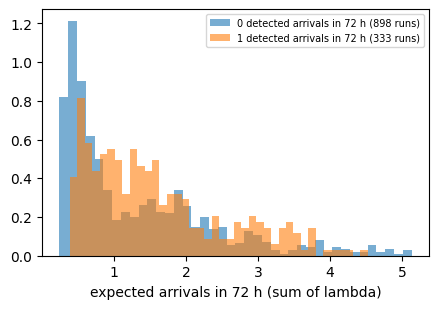

In [4]:
z = np.load(tse.CACHE_DIR / "2024_parts.npz")
lam = np.exp(z["eta"])
clean = z["m_lab"].all(axis=1)
expected = lam[clean].sum(axis=1)
observed = z["n_lab"][clean].sum(axis=1)
fig, ax = plt.subplots(figsize=(5, 3.2))
for o in (0, 1):
    ax.hist(expected[observed == o], bins=40, alpha=0.6, density=True,
            label=f"{o} detected arrivals in 72 h ({(observed == o).sum()} runs)")
ax.set_xlabel("expected arrivals in 72 h (sum of lambda)")
ax.legend(fontsize=7)
print(f"mean expected {expected.mean():.2f} vs detected {observed.mean():.2f} per run")

## Mean forecast and observation by lead and run regime, 2024 fold

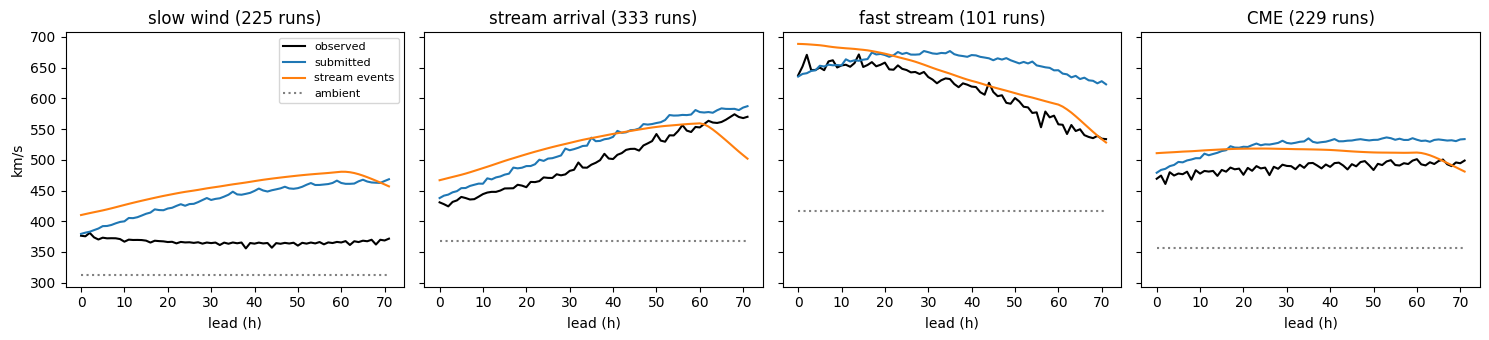

In [5]:
regime = z["regime"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, r in zip(axes, ("slow wind", "stream arrival", "fast stream", "CME"), strict=True):
    m = regime == r
    ax.plot(np.nanmean(z["obs"][m], 0), "k", label="observed")
    ax.plot(z["f_ref"][m].mean(0), label="submitted")
    ax.plot(z["f_events"][m].mean(0), label="stream events")
    ax.plot((z["ambient"][m, None] + 0 * z["stream"][m]).mean(0), "grey", ls=":", label="ambient")
    ax.set_title(f"{r} ({m.sum()} runs)")
    ax.set_xlabel("lead (h)")
axes[0].legend(fontsize=8)
axes[0].set_ylabel("km/s")
plt.tight_layout()

## Conclusion

Not built, stopped after the 2024 pilot fold (user decision, 2026-11-09).
- **Every variant is worse than the submitted model,** including as an input to it: from +2.5% (no current-sheet distance) to +20% (the main variant with arrival labels).
- **The speed loss swamps the arrival-label term.** The fitted rate is about 7× the detected rate, and the events act as a smooth background boost rather than discrete streams.
- **Additive events pile up on slow-wind runs** (+36% there). One first arrival does better than several additive ones.

Next: a Bayesian generative model in which the count, the timing and the event marks each have their own likelihood levels ([docs/bayes_stream.md](../../docs/bayes_stream.md)).
